In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [3]:
train_df=pd.read_csv(r"dataset\employee_attrition_train.csv")
test_df=pd.read_csv(r"dataset\employee_attrition_test.csv")

In [4]:
train_df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,50.0,No,Travel_Rarely,1126.0,Research & Development,1.0,2,Medical,1,997,...,3,80,1,32,1,2,5,4,1,3
1,36.0,No,Travel_Rarely,216.0,Research & Development,6.0,2,Medical,1,178,...,4,80,2,7,0,3,3,2,0,1
2,21.0,Yes,Travel_Rarely,337.0,Sales,7.0,1,Marketing,1,1780,...,2,80,0,1,3,3,1,0,1,0
3,50.0,No,Travel_Frequently,1246.0,Human Resources,NaN,3,Medical,1,644,...,3,80,1,32,2,3,32,5,10,7
4,52.0,No,Travel_Rarely,994.0,Research & Development,7.0,4,Life Sciences,1,1118,...,4,80,0,18,4,3,8,6,4,0


In [5]:
test_df.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,NaN,Travel_Rarely,866.0,Sales,NaN,3,Medical,1,1469,4,...,4,80,0,6,4,3,5,4,1,3
1,53.0,Travel_Rarely,1084.0,Research & Development,13.0,2,Medical,1,250,4,...,3,80,2,5,3,3,4,2,1,3
2,24.0,Travel_Rarely,240.0,Human Resources,22.0,1,Human Resources,1,1714,4,...,3,80,1,1,2,3,1,0,0,0
3,45.0,Travel_Rarely,1339.0,Research & Development,7.0,3,Life Sciences,1,86,2,...,3,80,1,25,2,3,1,0,0,0
4,36.0,Travel_Rarely,1396.0,Research & Development,NaN,2,Life Sciences,1,304,4,...,4,80,0,16,3,4,13,11,3,7


In [6]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 441 entries, 0 to 440
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       386 non-null    float64
 1   BusinessTravel            436 non-null    str    
 2   DailyRate                 427 non-null    float64
 3   Department                441 non-null    str    
 4   DistanceFromHome          387 non-null    float64
 5   Education                 441 non-null    int64  
 6   EducationField            441 non-null    str    
 7   EmployeeCount             441 non-null    int64  
 8   EmployeeNumber            441 non-null    int64  
 9   EnvironmentSatisfaction   441 non-null    int64  
 10  Gender                    441 non-null    str    
 11  HourlyRate                441 non-null    int64  
 12  JobInvolvement            441 non-null    int64  
 13  JobLevel                  441 non-null    int64  
 14  JobRole              

In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       893 non-null    float64
 1   Attrition                 1029 non-null   str    
 2   BusinessTravel            1024 non-null   str    
 3   DailyRate                 1002 non-null   float64
 4   Department                1029 non-null   str    
 5   DistanceFromHome          934 non-null    float64
 6   Education                 1029 non-null   int64  
 7   EducationField            1029 non-null   str    
 8   EmployeeCount             1029 non-null   int64  
 9   EmployeeNumber            1029 non-null   int64  
 10  EnvironmentSatisfaction   1029 non-null   int64  
 11  Gender                    1029 non-null   str    
 12  HourlyRate                1029 non-null   int64  
 13  JobInvolvement            1029 non-null   int64  
 14  JobLevel           

In [8]:
train_df.shape

(1029, 35)

In [9]:
train_df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [10]:
train_df.dtypes

Age                         float64
Attrition                       str
BusinessTravel                  str
DailyRate                   float64
Department                      str
DistanceFromHome            float64
Education                     int64
EducationField                  str
EmployeeCount                 int64
EmployeeNumber                int64
EnvironmentSatisfaction       int64
Gender                          str
HourlyRate                    int64
JobInvolvement                int64
JobLevel                      int64
JobRole                         str
JobSatisfaction               int64
MaritalStatus                   str
MonthlyIncome                 int64
MonthlyRate                   int64
NumCompaniesWorked            int64
Over18                          str
OverTime                        str
PercentSalaryHike             int64
PerformanceRating             int64
RelationshipSatisfaction      int64
StandardHours                 int64
StockOptionLevel            

In [11]:
train_df.isnull().sum()

Age                         136
Attrition                     0
BusinessTravel                5
DailyRate                    27
Department                    0
DistanceFromHome             95
Education                     0
EducationField                0
EmployeeCount                 0
EmployeeNumber                0
EnvironmentSatisfaction       0
Gender                        0
HourlyRate                    0
JobInvolvement                0
JobLevel                      0
JobRole                       0
JobSatisfaction               0
MaritalStatus                 5
MonthlyIncome                 0
MonthlyRate                   0
NumCompaniesWorked            0
Over18                        0
OverTime                      0
PercentSalaryHike             0
PerformanceRating             0
RelationshipSatisfaction      0
StandardHours                 0
StockOptionLevel              0
TotalWorkingYears             0
TrainingTimesLastYear         0
WorkLifeBalance               0
YearsAtC

In [12]:
train_df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,893.000000,1002.000000,934.000000,1029.000000,1029.0,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,...,1029.000000,1029.0,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000
mean,37.930571,800.528942,9.930407,2.892128,1.0,1024.367347,2.683188,66.680272,2.713314,2.043732,...,2.689990,80.0,0.822157,11.196307,2.782313,2.748299,6.942663,4.215743,2.119534,4.005831
std,9.395978,408.109828,8.421791,1.053541,0.0,606.301635,1.096829,20.474094,0.710146,1.118918,...,1.077767,0.0,0.874662,7.857581,1.283401,0.697278,6.068322,3.658595,3.108651,3.522574
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,31.000000,458.250000,2.000000,2.000000,1.0,496.000000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,37.000000,801.500000,8.000000,3.000000,1.0,1019.000000,3.000000,67.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,44.000000,1162.000000,16.000000,4.000000,1.0,1553.000000,4.000000,84.000000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,10.000000,7.000000,2.000000,7.000000
max,60.000000,1496.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,37.000000,18.000000,15.000000,17.000000


In [13]:
print("Total Number of Unique Values in Columns:")

for features in train_df:
    if features != "Attrition":
        print(f"{features}: (Data type: {train_df[features].dtype}) : {train_df[features].nunique()}")

Total Number of Unique Values in Columns:
Age: (Data type: float64) : 39
BusinessTravel: (Data type: str) : 3
DailyRate: (Data type: float64) : 692
Department: (Data type: str) : 3
DistanceFromHome: (Data type: float64) : 27
Education: (Data type: int64) : 5
EducationField: (Data type: str) : 6
EmployeeCount: (Data type: int64) : 1
EmployeeNumber: (Data type: int64) : 1029
EnvironmentSatisfaction: (Data type: int64) : 4
Gender: (Data type: str) : 2
HourlyRate: (Data type: int64) : 71
JobInvolvement: (Data type: int64) : 4
JobLevel: (Data type: int64) : 5
JobRole: (Data type: str) : 9
JobSatisfaction: (Data type: int64) : 4
MaritalStatus: (Data type: str) : 3
MonthlyIncome: (Data type: int64) : 963
MonthlyRate: (Data type: int64) : 1010
NumCompaniesWorked: (Data type: int64) : 10
Over18: (Data type: str) : 1
OverTime: (Data type: str) : 2
PercentSalaryHike: (Data type: int64) : 15
PerformanceRating: (Data type: int64) : 2
RelationshipSatisfaction: (Data type: int64) : 4
StandardHours: (

In [14]:
df=train_df.drop(["EmployeeCount","Over18","StandardHours","EmployeeNumber"],axis=1)

In [15]:
test_df=test_df.drop(["EmployeeCount","Over18","StandardHours","EmployeeNumber"],axis=1)

In [16]:
df.shape

(1029, 31)

In [17]:
test_df.shape

(441, 30)

In [18]:
print("Total Number of Unique Values in Columns:")

for features in df:
    if features != "Attrition":
        print(f"{features}: (Data type: {df[features].dtype}) : {df[features].nunique()}")

Total Number of Unique Values in Columns:
Age: (Data type: float64) : 39
BusinessTravel: (Data type: str) : 3
DailyRate: (Data type: float64) : 692
Department: (Data type: str) : 3
DistanceFromHome: (Data type: float64) : 27
Education: (Data type: int64) : 5
EducationField: (Data type: str) : 6
EnvironmentSatisfaction: (Data type: int64) : 4
Gender: (Data type: str) : 2
HourlyRate: (Data type: int64) : 71
JobInvolvement: (Data type: int64) : 4
JobLevel: (Data type: int64) : 5
JobRole: (Data type: str) : 9
JobSatisfaction: (Data type: int64) : 4
MaritalStatus: (Data type: str) : 3
MonthlyIncome: (Data type: int64) : 963
MonthlyRate: (Data type: int64) : 1010
NumCompaniesWorked: (Data type: int64) : 10
OverTime: (Data type: str) : 2
PercentSalaryHike: (Data type: int64) : 15
PerformanceRating: (Data type: int64) : 2
RelationshipSatisfaction: (Data type: int64) : 4
StockOptionLevel: (Data type: int64) : 4
TotalWorkingYears: (Data type: int64) : 40
TrainingTimesLastYear: (Data type: int64)

In [19]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,50.0,No,Travel_Rarely,1126.0,Research & Development,1.0,2,Medical,4,Male,...,4,3,1,32,1,2,5,4,1,3
1,36.0,No,Travel_Rarely,216.0,Research & Development,6.0,2,Medical,2,Male,...,4,4,2,7,0,3,3,2,0,1
2,21.0,Yes,Travel_Rarely,337.0,Sales,7.0,1,Marketing,2,Male,...,3,2,0,1,3,3,1,0,1,0
3,50.0,No,Travel_Frequently,1246.0,Human Resources,NaN,3,Medical,1,Male,...,3,3,1,32,2,3,32,5,10,7
4,52.0,No,Travel_Rarely,994.0,Research & Development,7.0,4,Life Sciences,2,Male,...,3,4,0,18,4,3,8,6,4,0


In [20]:
import pandas as pd

pd.set_option("display.max_columns", None)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,50.0,No,Travel_Rarely,1126.0,Research & Development,1.0,2,Medical,4,Male,66,3,4,Research Director,4,Divorced,17399,6615,9,No,22,4,3,1,32,1,2,5,4,1,3
1,36.0,No,Travel_Rarely,216.0,Research & Development,6.0,2,Medical,2,Male,84,3,2,Manufacturing Director,2,Divorced,4941,2819,6,No,20,4,4,2,7,0,3,3,2,0,1
2,21.0,Yes,Travel_Rarely,337.0,Sales,7.0,1,Marketing,2,Male,31,3,1,Sales Representative,2,Single,2679,4567,1,No,13,3,2,0,1,3,3,1,0,1,0
3,50.0,No,Travel_Frequently,1246.0,Human Resources,NaN,3,Medical,1,Male,99,3,5,Manager,2,Married,18200,7999,1,No,11,3,3,1,32,2,3,32,5,10,7
4,52.0,No,Travel_Rarely,994.0,Research & Development,7.0,4,Life Sciences,2,Male,87,3,3,Healthcare Representative,2,Single,10445,15322,7,No,19,3,4,0,18,4,3,8,6,4,0


In [21]:
c=(df['Attrition'].value_counts())
c

Attrition
No     853
Yes    176
Name: count, dtype: int64

In [22]:
c.values

array([853, 176], dtype=int64)

<BarContainer object of 2 artists>

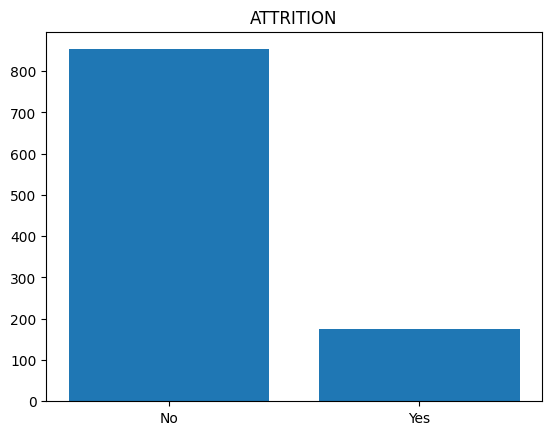

In [23]:
plt.title("ATTRITION")
plt.bar(c.index,c.values)

In [24]:
c1=df['OverTime'].value_counts()
c1

OverTime
No     731
Yes    298
Name: count, dtype: int64

In [25]:
df[["OverTime", "Attrition"]].value_counts()

OverTime  Attrition
No        No           654
Yes       No           199
          Yes           99
No        Yes           77
Name: count, dtype: int64

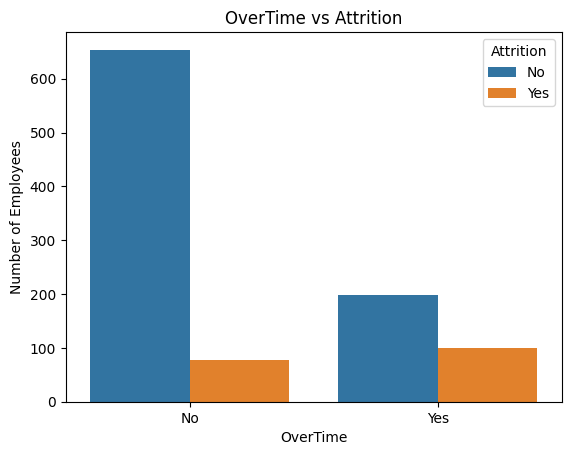

In [26]:
sns.countplot(
    x="OverTime",
    hue="Attrition",
    data=df
)
plt.title("OverTime vs Attrition")
plt.xlabel("OverTime")
plt.ylabel("Number of Employees")

plt.show()

In [27]:
df[["Department","Attrition"]].value_counts()

Department              Attrition
Research & Development  No           577
Sales                   No           242
Research & Development  Yes           99
Sales                   Yes           69
Human Resources         No            34
                        Yes            8
Name: count, dtype: int64

In [28]:
8/(8+34)

0.19047619047619047

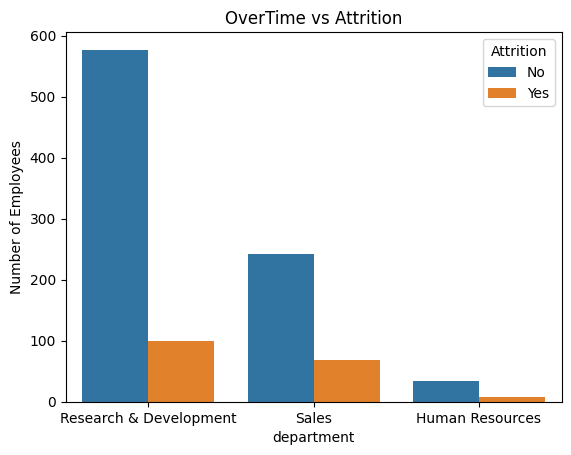

In [29]:
sns.countplot(
    x="Department",
    hue="Attrition",
    data=df
)
plt.title("OverTime vs Attrition")
plt.xlabel("department")
plt.ylabel("Number of Employees")

plt.show()

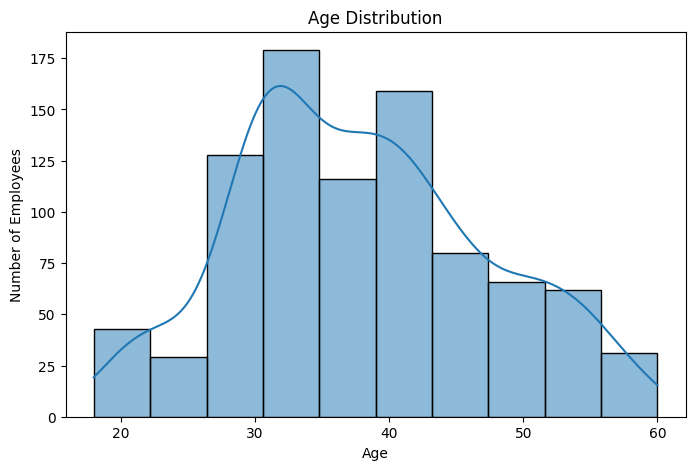

In [30]:
plt.figure(figsize=(8,5))

sns.histplot(
    x="Age",
    data=df,
    bins=10,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

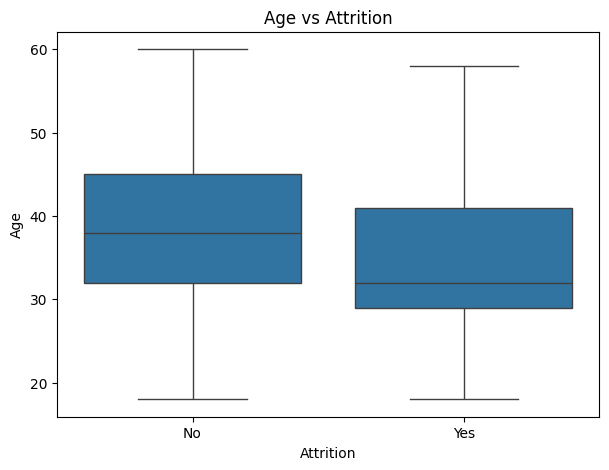

In [31]:
plt.figure(figsize=(7,5))

sns.boxplot(
    x="Attrition",
    y="Age",
    data=df
)

plt.title("Age vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Age")

plt.show()

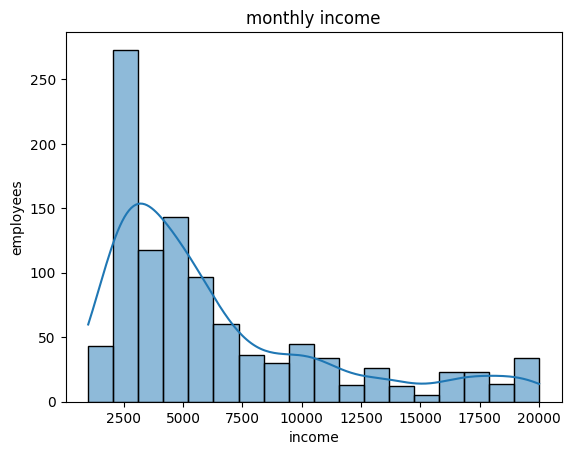

In [32]:
sns.histplot(
    x="MonthlyIncome",
    data=df,
    kde=True
)
plt.title("monthly income")
plt.xlabel("income")
plt.ylabel("employees")
plt.show()

<Axes: xlabel='Attrition', ylabel='MonthlyIncome'>

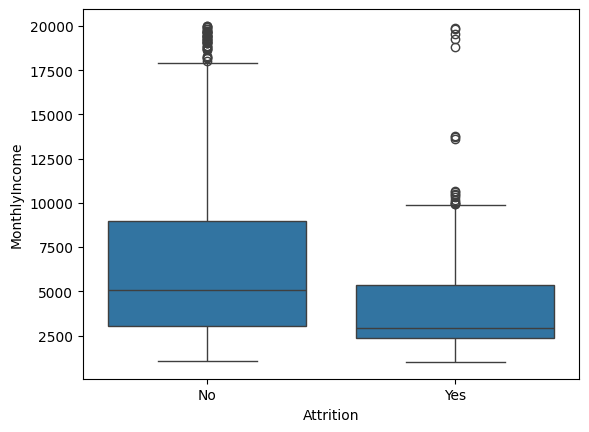

In [33]:
sns.boxplot(
    x="Attrition",
    y='MonthlyIncome',
    data=df
)

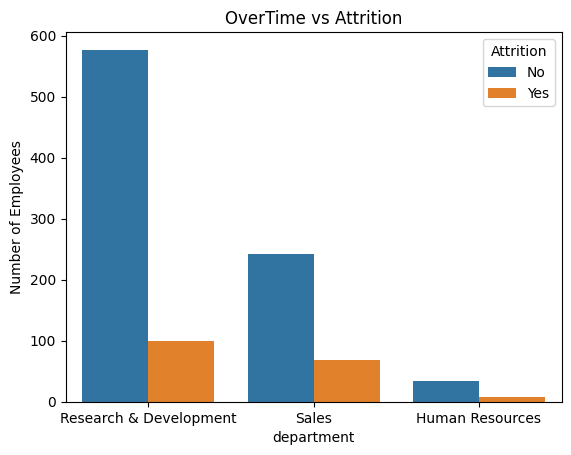

In [34]:
sns.countplot(
    x="Department",
    hue="Attrition",
    data=df
)
plt.title("OverTime vs Attrition")
plt.xlabel("department")
plt.ylabel("Number of Employees")

plt.show()

In [35]:
numeric_df = df.select_dtypes(include="number")

corr_matrix = numeric_df.corr()

In [36]:
corr_matrix

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.023845,-0.036895,0.226646,-0.024051,0.019754,0.024176,0.506348,0.007670,0.492360,0.018697,0.298354,0.011593,0.007457,0.062533,0.023282,0.676650,-0.026077,-0.042949,0.291798,0.218028,0.178679,0.186070
DailyRate,0.023845,1.000000,-0.018783,-0.056701,-0.001438,0.028555,0.047225,0.021386,0.022260,0.023055,-0.003860,0.041677,0.016684,0.018240,0.029849,0.049149,0.007548,0.022518,-0.053567,-0.041877,-0.019262,-0.049283,-0.056317
DistanceFromHome,-0.036895,-0.018783,1.000000,0.005009,-0.041260,-0.007381,0.026350,0.002220,0.015920,-0.018486,0.061144,-0.035275,0.051717,0.041723,0.014434,0.018559,-0.005680,-0.040232,-0.020954,-0.002579,0.003508,-0.024982,0.017107
Education,0.226646,-0.056701,0.005009,1.000000,-0.032129,0.012786,0.049639,0.093952,0.001742,0.093543,-0.052047,0.119453,-0.007075,-0.025992,-0.005492,0.025609,0.159551,-0.041845,0.018620,0.070545,0.087055,0.057998,0.083523
EnvironmentSatisfaction,-0.024051,-0.001438,-0.041260,-0.032129,1.000000,-0.038216,-0.015561,-0.005345,-0.045906,-0.013881,0.067739,-0.001804,-0.012362,0.002318,-0.016510,0.006108,-0.002371,-0.004123,0.025369,0.015683,0.019474,0.035938,-0.009592
HourlyRate,0.019754,0.028555,-0.007381,0.012786,-0.038216,1.000000,0.043600,-0.047287,-0.091423,-0.033674,0.000859,0.008938,-0.003659,-0.002279,-0.015076,0.021483,-0.015391,-0.001245,-0.008096,-0.036649,-0.027986,-0.058669,-0.029499
JobInvolvement,0.024176,0.047225,0.026350,0.049639,-0.015561,0.043600,1.000000,-0.002570,-0.013561,-0.002592,-0.057787,0.014010,-0.023604,-0.044825,0.038824,0.032162,0.008527,-0.009838,-0.022104,-0.009461,0.014094,-0.039542,0.049666
JobLevel,0.506348,0.021386,0.002220,0.093952,-0.005345,-0.047287,-0.002570,1.000000,-0.011140,0.952756,0.048007,0.154803,-0.018906,-0.007530,0.021739,-0.006955,0.786130,-0.001493,0.051527,0.544920,0.418767,0.350313,0.365449
JobSatisfaction,0.007670,0.022260,0.015920,0.001742,-0.045906,-0.091423,-0.013561,-0.011140,1.000000,-0.020463,-0.001979,-0.055757,0.018167,0.007691,-0.006388,0.007461,-0.020868,0.003154,-0.041340,-0.005842,0.005784,-0.016437,-0.017440
MonthlyIncome,0.492360,0.023055,-0.018486,0.093543,-0.013881,-0.033674,-0.002592,0.952756,-0.020463,1.000000,0.040676,0.168976,-0.020387,-0.010082,0.032840,-0.007745,0.773499,-0.002389,0.040840,0.525311,0.396541,0.346647,0.336437


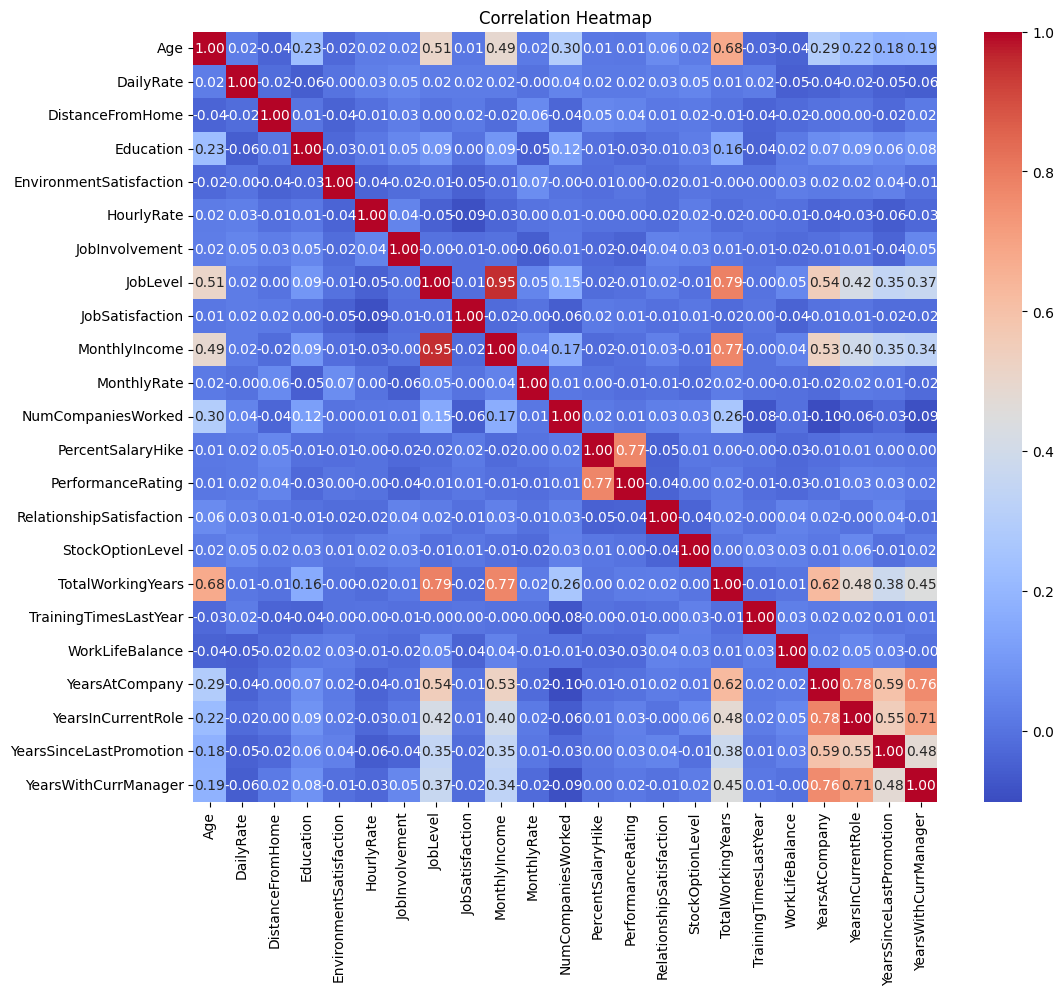

In [37]:
plt.figure(figsize=(12,10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [38]:
strclmn=df.select_dtypes(include="object").columns

C:\Users\user\AppData\Local\Temp\ipykernel_21692\459281298.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  strclmn=df.select_dtypes(include="object").columns


In [39]:
for i in strclmn:
    print(df[i].value_counts())
    

Attrition
No     853
Yes    176
Name: count, dtype: int64
BusinessTravel
Travel_Rarely        723
Travel_Frequently    199
Non-Travel           102
Name: count, dtype: int64
Department
Research & Development    676
Sales                     311
Human Resources            42
Name: count, dtype: int64
EducationField
Life Sciences       426
Medical             328
Marketing           110
Technical Degree     82
Other                66
Human Resources      17
Name: count, dtype: int64
Gender
Male      617
Female    412
Name: count, dtype: int64
JobRole
Sales Executive              217
Research Scientist           214
Laboratory Technician        179
Manufacturing Director        95
Healthcare Representative     89
Manager                       73
Sales Representative          66
Research Director             62
Human Resources               34
Name: count, dtype: int64
MaritalStatus
Married     474
Single      320
Divorced    230
Name: count, dtype: int64
OverTime
No     731
Yes    298
Nam

In [40]:
le=LabelEncoder()

In [41]:
label_columns=[ "Attrition","Gender","OverTime"]

for i in label_columns:
    df[i]=le.fit_transform(df[i])
    

In [42]:
label_columns=["Gender","OverTime"]

for i in label_columns:
    test_df[i]=le.fit_transform(test_df[i])
    

In [43]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,50.0,0,Travel_Rarely,1126.0,Research & Development,1.0,2,Medical,4,1,66,3,4,Research Director,4,Divorced,17399,6615,9,0,22,4,3,1,32,1,2,5,4,1,3
1,36.0,0,Travel_Rarely,216.0,Research & Development,6.0,2,Medical,2,1,84,3,2,Manufacturing Director,2,Divorced,4941,2819,6,0,20,4,4,2,7,0,3,3,2,0,1
2,21.0,1,Travel_Rarely,337.0,Sales,7.0,1,Marketing,2,1,31,3,1,Sales Representative,2,Single,2679,4567,1,0,13,3,2,0,1,3,3,1,0,1,0
3,50.0,0,Travel_Frequently,1246.0,Human Resources,NaN,3,Medical,1,1,99,3,5,Manager,2,Married,18200,7999,1,0,11,3,3,1,32,2,3,32,5,10,7
4,52.0,0,Travel_Rarely,994.0,Research & Development,7.0,4,Life Sciences,2,1,87,3,3,Healthcare Representative,2,Single,10445,15322,7,0,19,3,4,0,18,4,3,8,6,4,0


In [44]:
one_hot_columns=[ "BusinessTravel","Department","EducationField","JobRole","MaritalStatus"]

In [45]:
pd.DataFrame(df,columns=one_hot_columns)

,BusinessTravel,Department,EducationField,JobRole,MaritalStatus
0,Travel_Rarely,Research & Development,Medical,Research Director,Divorced
1,Travel_Rarely,Research & Development,Medical,Manufacturing Director,Divorced
2,Travel_Rarely,Sales,Marketing,Sales Representative,Single
3,Travel_Frequently,Human Resources,Medical,Manager,Married
4,Travel_Rarely,Research & Development,Life Sciences,Healthcare Representative,Single
...,...,...,...,...,...
1024,Travel_Rarely,Research & Development,Life Sciences,Laboratory Technician,Married
1025,Travel_Rarely,Research & Development,Life Sciences,Healthcare Representative,Single
1026,Travel_Frequently,Research & Development,Life Sciences,Research Scientist,Married
1027,Travel_Rarely,Research & Development,Other,Laboratory Technician,Married


In [46]:
df = pd.get_dummies(df,columns=one_hot_columns)

In [47]:
test_df = pd.get_dummies(test_df,columns=one_hot_columns)

In [48]:
df.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Healthcare Representative,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single
0,50.0,0,1126.0,1.0,2,4,1,66,3,4,4,17399,6615,9,0,22,4,3,1,32,1,2,5,4,1,3,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False
1,36.0,0,216.0,6.0,2,2,1,84,3,2,2,4941,2819,6,0,20,4,4,2,7,0,3,3,2,0,1,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True,False,False
2,21.0,1,337.0,7.0,1,2,1,31,3,1,2,2679,4567,1,0,13,3,2,0,1,3,3,1,0,1,0,False,False,True,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,50.0,0,1246.0,NaN,3,1,1,99,3,5,2,18200,7999,1,0,11,3,3,1,32,2,3,32,5,10,7,False,True,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,True,False
4,52.0,0,994.0,7.0,4,2,1,87,3,3,2,10445,15322,7,0,19,3,4,0,18,4,3,8,6,4,0,False,False,True,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True


In [49]:
df.shape

(1029, 50)

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 50 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                893 non-null    float64
 1   Attrition                          1029 non-null   int32  
 2   DailyRate                          1002 non-null   float64
 3   DistanceFromHome                   934 non-null    float64
 4   Education                          1029 non-null   int64  
 5   EnvironmentSatisfaction            1029 non-null   int64  
 6   Gender                             1029 non-null   int32  
 7   HourlyRate                         1029 non-null   int64  
 8   JobInvolvement                     1029 non-null   int64  
 9   JobLevel                           1029 non-null   int64  
 10  JobSatisfaction                    1029 non-null   int64  
 11  MonthlyIncome                      1029 non-null   int64  
 12  Mon

In [51]:
df.isnull().sum()

Age                                  136
Attrition                              0
DailyRate                             27
DistanceFromHome                      95
Education                              0
EnvironmentSatisfaction                0
Gender                                 0
HourlyRate                             0
JobInvolvement                         0
JobLevel                               0
JobSatisfaction                        0
MonthlyIncome                          0
MonthlyRate                            0
NumCompaniesWorked                     0
OverTime                               0
PercentSalaryHike                      0
PerformanceRating                      0
RelationshipSatisfaction               0
StockOptionLevel                       0
TotalWorkingYears                      0
TrainingTimesLastYear                  0
WorkLifeBalance                        0
YearsAtCompany                         0
YearsInCurrentRole                     0
YearsSinceLastPr

In [52]:
df.duplicated().sum()

0

In [53]:
test_df.duplicated().sum()

0

In [54]:
df[["Age", "DailyRate", "DistanceFromHome"]].describe()

,Age,DailyRate,DistanceFromHome
count,893.000000,1002.000000,934.000000
mean,37.930571,800.528942,9.930407
std,9.395978,408.109828,8.421791
min,18.000000,102.000000,1.000000
25%,31.000000,458.250000,2.000000
50%,37.000000,801.500000,8.000000
75%,44.000000,1162.000000,16.000000
max,60.000000,1496.000000,29.000000


In [55]:
df["Age"]=df["Age"].fillna(df["Age"].mean())
df["DailyRate"] = df["DailyRate"].fillna(df["DailyRate"].mean())
df["DistanceFromHome"] = df["DistanceFromHome"].fillna(df["DistanceFromHome"].median())

In [56]:
test_df["Age"]=test_df["Age"].fillna(test_df["Age"].mean())
test_df["DailyRate"] = test_df["DailyRate"].fillna(test_df["DailyRate"].mean())
test_df["DistanceFromHome"] = test_df["DistanceFromHome"].fillna(test_df["DistanceFromHome"].median())

In [57]:
df.isnull().sum()

Age                                  0
Attrition                            0
DailyRate                            0
DistanceFromHome                     0
Education                            0
EnvironmentSatisfaction              0
Gender                               0
HourlyRate                           0
JobInvolvement                       0
JobLevel                             0
JobSatisfaction                      0
MonthlyIncome                        0
MonthlyRate                          0
NumCompaniesWorked                   0
OverTime                             0
PercentSalaryHike                    0
PerformanceRating                    0
RelationshipSatisfaction             0
StockOptionLevel                     0
TotalWorkingYears                    0
TrainingTimesLastYear                0
WorkLifeBalance                      0
YearsAtCompany                       0
YearsInCurrentRole                   0
YearsSinceLastPromotion              0
YearsWithCurrManager     

In [58]:
test_df.isnull().sum()

Age                                  0
DailyRate                            0
DistanceFromHome                     0
Education                            0
EnvironmentSatisfaction              0
Gender                               0
HourlyRate                           0
JobInvolvement                       0
JobLevel                             0
JobSatisfaction                      0
MonthlyIncome                        0
MonthlyRate                          0
NumCompaniesWorked                   0
OverTime                             0
PercentSalaryHike                    0
PerformanceRating                    0
RelationshipSatisfaction             0
StockOptionLevel                     0
TotalWorkingYears                    0
TrainingTimesLastYear                0
WorkLifeBalance                      0
YearsAtCompany                       0
YearsInCurrentRole                   0
YearsSinceLastPromotion              0
YearsWithCurrManager                 0
BusinessTravel_Non-Travel

In [59]:
X=df.drop("Attrition",axis=1)
y=df["Attrition"]

In [60]:
print(X.shape)
print(y.shape)

(1029, 49)
(1029,)


In [61]:
scaler=StandardScaler()

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [63]:
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_test)

In [64]:
model=LogisticRegression()

In [65]:
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [66]:
model.coef_

array([[-0.10158793, -0.05701808,  0.38637959,  0.11004809, -0.5476756 ,
         0.1868951 , -0.01301582, -0.36343295,  0.02676955, -0.38282092,
        -0.06392293,  0.19673922,  0.6485844 ,  0.97313857,  0.0637675 ,
        -0.09746259, -0.21112743,  0.02075546, -0.85624925, -0.20948062,
        -0.32822143,  0.99462568, -0.85244912,  0.37541739, -0.19409354,
        -0.41298892,  0.37719844,  0.1081164 , -0.14952715,  0.14091915,
        -0.08160486, -0.02616954, -0.12341315,  0.02661192, -0.04971076,
         0.03952514,  0.24488883, -0.39403952,  0.32202504,  0.20404466,
         0.1012852 , -0.18024273, -0.54835385, -0.14779826,  0.25028323,
         0.39124275, -0.44792433, -0.29408652,  0.36835032]])

In [67]:
model.intercept_

array([-2.68008259])

In [68]:


weights = pd.DataFrame({
    "Feature": X.columns,
    "Weight": model.coef_[0]
})

weights

,Feature,Weight
0,Age,-0.101588
1,DailyRate,-0.057018
2,DistanceFromHome,0.386380
3,Education,0.110048
4,EnvironmentSatisfaction,-0.547676
5,Gender,0.186895
6,HourlyRate,-0.013016
7,JobInvolvement,-0.363433
8,JobLevel,0.026770
9,JobSatisfaction,-0.382821


In [69]:
weights.sort_values(by="Weight", ascending=False)

,Feature,Weight
21,YearsAtCompany,0.994626
13,OverTime,0.973139
12,NumCompaniesWorked,0.648584
45,JobRole_Sales Representative,0.391243
2,DistanceFromHome,0.386380
26,BusinessTravel_Travel_Frequently,0.377198
23,YearsSinceLastPromotion,0.375417
48,MaritalStatus_Single,0.368350
38,JobRole_Human Resources,0.322025
44,JobRole_Sales Executive,0.250283


In [70]:
ypred=model.predict(X_valid)

In [71]:
ypred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0])

In [72]:
print(classification_report(y_test, ypred))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92       171
           1       0.61      0.40      0.48        35

    accuracy                           0.85       206
   macro avg       0.75      0.67      0.70       206
weighted avg       0.84      0.85      0.84       206



In [73]:
print(confusion_matrix(y_test, ypred))

[[162   9]
 [ 21  14]]


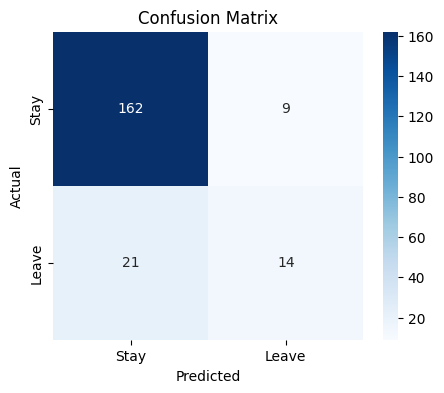

In [74]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, ypred)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Leave"],
    yticklabels=["Stay", "Leave"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [75]:
test_df1 = scaler.transform(test_df)

In [76]:
ypred_test = model.predict(test_df1)

In [77]:
ypred_test

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [78]:
test_df['Attrition'] = ypred_test

In [79]:
type(test_df)

pandas.DataFrame

In [80]:
type(ypred_test)

numpy.ndarray

In [81]:
test_df

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Human Resources,Department_Research & Development,Department_Sales,EducationField_Human Resources,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Healthcare Representative,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,Attrition
0,38.0,866.0,8.0,3,4,1,84,3,2,1,8463,23490,0,0,18,3,4,0,6,4,3,5,4,1,3,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,True,0
1,53.0,1084.0,13.0,2,4,0,57,4,2,1,4450,26250,1,0,11,3,3,2,5,3,3,4,2,1,3,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True,False,False,0
2,24.0,240.0,22.0,1,4,1,58,1,1,3,1555,11585,1,0,11,3,3,1,1,2,3,1,0,0,0,False,False,True,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,0
3,45.0,1339.0,7.0,3,2,1,59,3,3,1,9724,18787,2,0,17,3,3,1,25,2,3,1,0,0,0,False,False,True,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,0
4,36.0,1396.0,8.0,2,4,1,62,3,2,2,5914,9945,8,0,16,3,4,0,16,3,4,13,11,3,7,False,False,True,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
436,33.0,430.0,7.0,3,4,1,54,3,2,1,4373,17456,0,0,14,3,1,2,5,2,3,4,3,0,3,False,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False,0
437,27.0,210.0,1.0,1,3,1,73,3,2,2,6349,22107,0,1,13,3,4,1,6,0,3,5,4,1,4,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,0
438,38.0,1157.0,2.0,4,1,1,84,1,1,4,3464,24737,5,1,13,3,4,0,5,4,2,3,2,2,2,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,1
439,39.0,1383.0,2.0,3,4,0,42,2,2,4,5204,7790,8,0,11,3,3,2,13,2,3,5,4,0,4,False,False,True,True,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,0


In [82]:
weights = pd.DataFrame({
    "Feature": X.columns,
    "Weight": model.coef_[0]
})

weights.sort_values(by="Weight", ascending=False)

,Feature,Weight
21,YearsAtCompany,0.994626
13,OverTime,0.973139
12,NumCompaniesWorked,0.648584
45,JobRole_Sales Representative,0.391243
2,DistanceFromHome,0.386380
26,BusinessTravel_Travel_Frequently,0.377198
23,YearsSinceLastPromotion,0.375417
48,MaritalStatus_Single,0.368350
38,JobRole_Human Resources,0.322025
44,JobRole_Sales Executive,0.250283


In [83]:
import joblib

In [84]:
joblib.dump(model,"employee_attrition_model.pkl")
joblib.dump(scaler,"employee_attrition_scaler.pkl")

['employee_attrition_scaler.pkl']

In [85]:
print(test_df.columns)

Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate',
       'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike',
       'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager', 'BusinessTravel_Non-Travel',
       'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely',
       'Department_Human Resources', 'Department_Research & Development',
       'Department_Sales', 'EducationField_Human Resources',
       'EducationField_Life Sciences', 'EducationField_Marketing',
       'EducationField_Medical', 'EducationField_Other',
       'EducationField_Technical Degree', 'JobRole_Healthcare Representative',
       'JobRole_Human Resources', 'Jo

In [86]:
remove_cols = [
    "PercentSalaryHike",
    "EducationField_Other",
    "JobLevel",
    "EducationField_Marketing",
    "StockOptionLevel"
]

X_new = X.drop(columns=remove_cols)

In [87]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X_new, y, test_size=0.2, random_state=42)

In [88]:
scaler.fit_transform(X_train1)
X_test1= scaler.transform(X_test1)

In [89]:
model_new = LogisticRegression()
model_new.fit(X_train1, y_train1)

c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [90]:
y_pred1=model_new.predict(X_test1)

c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [91]:
print(classification_report(y_test1, y_pred1))
print(confusion_matrix(y_test1, y_pred1))
print("Accuracy:", accuracy_score(y_test1, y_pred1))

              precision    recall  f1-score   support

           0       0.96      0.56      0.70       171
           1       0.29      0.89      0.44        35

    accuracy                           0.61       206
   macro avg       0.62      0.72      0.57       206
weighted avg       0.85      0.61      0.66       206

[[95 76]
 [ 4 31]]
Accuracy: 0.6116504854368932


In [92]:
raw_df=pd.read_csv(r"dataset\employee_attrition_train.csv")

In [93]:
features = [
    "Age",
    "Gender",
    "Department",
    "BusinessTravel",
    "DistanceFromHome",
    "MonthlyIncome",
    "OverTime",
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "YearsAtCompany",
    "TotalWorkingYears"
]

X = raw_df[features].copy()
y = raw_df["Attrition"]

In [94]:
X.head()

,Age,Gender,Department,BusinessTravel,DistanceFromHome,MonthlyIncome,OverTime,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,YearsAtCompany,TotalWorkingYears
0,50.0,Male,Research & Development,Travel_Rarely,1.0,17399,No,4,4,2,5,32
1,36.0,Male,Research & Development,Travel_Rarely,6.0,4941,No,2,2,3,3,7
2,21.0,Male,Sales,Travel_Rarely,7.0,2679,No,2,2,3,1,1
3,50.0,Male,Human Resources,Travel_Frequently,NaN,18200,No,2,1,3,32,32
4,52.0,Male,Research & Development,Travel_Rarely,7.0,10445,No,2,2,3,8,18


In [95]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      893 non-null    float64
 1   Gender                   1029 non-null   str    
 2   Department               1029 non-null   str    
 3   BusinessTravel           1024 non-null   str    
 4   DistanceFromHome         934 non-null    float64
 5   MonthlyIncome            1029 non-null   int64  
 6   OverTime                 1029 non-null   str    
 7   JobSatisfaction          1029 non-null   int64  
 8   EnvironmentSatisfaction  1029 non-null   int64  
 9   WorkLifeBalance          1029 non-null   int64  
 10  YearsAtCompany           1029 non-null   int64  
 11  TotalWorkingYears        1029 non-null   int64  
dtypes: float64(2), int64(6), str(4)
memory usage: 134.0 KB


In [96]:
y.info()

<class 'pandas.Series'>
RangeIndex: 1029 entries, 0 to 1028
Series name: Attrition
Non-Null Count  Dtype
--------------  -----
1029 non-null   str  
dtypes: str(1)
memory usage: 10.3 KB


In [97]:
X[['Age','DistanceFromHome']].describe()

,Age,DistanceFromHome
count,893.000000,934.000000
mean,37.930571,9.930407
std,9.395978,8.421791
min,18.000000,1.000000
25%,31.000000,2.000000
50%,37.000000,8.000000
75%,44.000000,16.000000
max,60.000000,29.000000


In [98]:
X['Age'] = X['Age'].fillna(X['Age'].mean())
X['DistanceFromHome'] = X['DistanceFromHome'].fillna(X['DistanceFromHome'].median())

In [99]:
X['BusinessTravel']=X['BusinessTravel'].fillna(X['BusinessTravel'].mode()[0])

In [108]:
gender_encoder = LabelEncoder()
overtime_encoder = LabelEncoder()

X["Gender"] = gender_encoder.fit_transform(X["Gender"])
X["OverTime"] = overtime_encoder.fit_transform(X["OverTime"])

In [101]:
features_hot=['Department','BusinessTravel']
X = pd.get_dummies(X, columns=features_hot)

In [115]:
X.columns.tolist()

['Age',
 'Gender',
 'DistanceFromHome',
 'MonthlyIncome',
 'OverTime',
 'JobSatisfaction',
 'EnvironmentSatisfaction',
 'WorkLifeBalance',
 'YearsAtCompany',
 'TotalWorkingYears',
 'Department_Human Resources',
 'Department_Research & Development',
 'Department_Sales',
 'BusinessTravel_Non-Travel',
 'BusinessTravel_Travel_Frequently',
 'BusinessTravel_Travel_Rarely']

In [116]:
joblib.dump(X.columns.tolist(), "training_columns.pkl")

['training_columns.pkl']

In [102]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=42)

In [110]:
scaler_new = StandardScaler()
X_train_scaled = scaler_new.fit_transform(X_train2)
X_test_scaled = scaler_new.transform(X_test2)

In [112]:
f_model = LogisticRegression()
f_model.fit(X_train_scaled, y_train2)

y_pred = f_model.predict(X_test_scaled)

In [105]:
f_model.coef_

array([[-0.15963615,  0.15215862,  0.20075016, -0.3464197 ,  0.77765734,
        -0.35048605, -0.40876779, -0.24749355, -0.04916412, -0.37527659,
        -0.01684846, -0.18925225,  0.20298494, -0.36966238,  0.26337881,
         0.01696672]])

In [113]:
print(classification_report(y_test2, y_pred))

              precision    recall  f1-score   support

          No       0.87      0.97      0.92       171
         Yes       0.67      0.29      0.40        35

    accuracy                           0.85       206
   macro avg       0.77      0.63      0.66       206
weighted avg       0.83      0.85      0.83       206



In [114]:
joblib.dump(f_model, "employee_attrition_model.pkl")
joblib.dump(scaler_new, "employee_attrition_scaler.pkl")
joblib.dump(gender_encoder, "gender_encoder.pkl")
joblib.dump(overtime_encoder, "overtime_encoder.pkl")

['overtime_encoder.pkl']